In [1]:
import copy
import numpy as np
from pathlib import Path
import cv2
import torch
import torch.nn.functional as f
from matplotlib import pyplot as plt
import pandas as pd
from torchvision import datasets,transforms
from torch.utils.data.dataloader import DataLoader
from torch.utils.data import random_split
from torchvision.utils import make_grid
from tqdm import tqdm
import math
from torch.utils.data import Subset
import time

In [2]:
!pip uninstall -y cnn-internals
!pip install  --no-cache-dir  git+https://github.com/LoayMohamedAhmed/Cifar-training-with-CNN.git

  Cloning https://github.com/LoayMohamedAhmed/Cifar-training-with-CNN.git to /tmp/pip-req-build-qff46zj7
  Running command git clone --filter=blob:none --quiet https://github.com/LoayMohamedAhmed/Cifar-training-with-CNN.git /tmp/pip-req-build-qff46zj7
  Resolved https://github.com/LoayMohamedAhmed/Cifar-training-with-CNN.git to commit 0d7136d71de029b4f7dd92769f7b1592e325cc30
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for cnn_internals: filename=cnn_internals-0.1-py3-none-any.whl size=18666 sha256=4e5bbc800b4a0e358fb940e6b1f36eafea4a27a87c33a794c6addd6c975d07f0
  Stored in directory: /tmp/pip-ephem-wheel-cache-7l8s3r25/wheels/9a/43/44/17c731de8c5a36b9ab2630d16fab76de143e908a29ca98e937
Successfully built cnn_internals


In [3]:
from Src.layers import ReLU,BatchNorm2d,Dropout, Linear, Softmax, Flatten, BatchNorm
from Src.Conv import Conv2d, Pooling2d
from Src.optim import Adams_W, LR_schedule, cross_entropy_Loss, total_loss_accur, max_lr_finder
from Src.containers import Sequential
from Src.models.LeNet import LeNet_arch
from Utils.diagnostics import plot_gradient_flow, gradient_ascent, dead_percentage_hook, sanity_check, grad_cam
from Tracking.visualization import visualize_image, display_layer_out, loss_accuracy_visualization
from Src.engine import Train_engine

# Layers
register_forward_hook() method must be implemented in each layer becasue it allow us to control the input and the output of the layer once the forwad pass complete, it takes a special hook function with (model,input,output) parameters where the model is the layer input is the input to that layer and output is the output of that layers, look at the implementation in **relu** to understand how it receive and excute the hook

# Load data

In [4]:
# adda transformation to data when loading it
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean = (0.4915, 0.4824, 0.4469),
        std = (0.2469, 0.2433, 0.2615)
    )
])
tr_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomCrop(32,4), # create a random translation to break the location correlation
    #transforms.RandomResizedCrop(32,scale=(0.8,1)), # zoom in effect
    transforms.RandomHorizontalFlip(p=0.5), # a probability of 0.5 that the image is floped
    transforms.RandomRotation(degrees=(-10,10),interpolation= transforms.InterpolationMode.BILINEAR,fill=0,expand= False),
    transforms.ColorJitter(brightness = 0.2, contrast = 0.2, saturation = 0.2),
    transforms.Normalize(
        mean = (0.4915, 0.4824, 0.4469),
        std = (0.2469, 0.2433, 0.2615)
    )
])
train_data = datasets.CIFAR10(root='./data', train = True,download = True,transform = tr_transform)
val_data = datasets.CIFAR10(root='./data', train = True,download = True,transform = val_transform)

100%|██████████| 170M/170M [10:48<00:00, 263kB/s]


In [5]:
# devide the data into train and validation sets
g = torch.Generator().manual_seed(2882001)
data_len = len(train_data)
train_size = int(0.8 * data_len)
val_size = data_len - train_size
#create shuffle indices 
indices = torch.randperm(data_len, generator = g)# craete a shuffeld list of indices from 0 to data_len-1
train_idx = indices[:train_size] # list of training indices
val_idx = indices[train_size:]  # list of validation indices
data_tr, data_val = Subset(train_data , train_idx), Subset(val_data , val_idx)
#data_tr , data_val =random_split(val_data,[train_size,val_size],generator = g)

In [6]:
data_tr_dl = DataLoader(data_tr, batch_size = 64, shuffle = True)
data_val_dl = DataLoader(data_val, batch_size = 64, shuffle = True)

In [7]:
#next(iter(data_tr_dl))[0][0].shape
len(data_val_dl)

157

# construct model

In [8]:
batch_sizes = [2**x for x in range(5,11)]
batch = batch_sizes[1]
hidden_sizes = [100*x for x in range(1,10)]
LRs = np.linspace(-7,0,len(data_tr)//batch)
lr_algo = ['step decay','exponential','cosin']
epochs = 60
iterations = len(data_tr)//batch
lambdas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
drop_rates = [0.1 * x for x in range(1,10)]


## architectures
i will try different architectures blocks for backbone
sequential **(LeNet-5)**
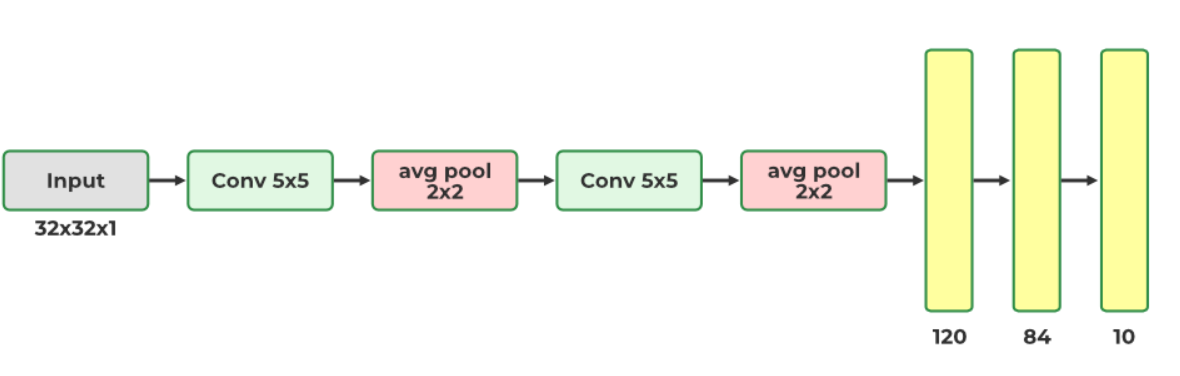


lr finder iterations: 100%|██████████| 625/625 [05:25<00:00,  1.92it/s]


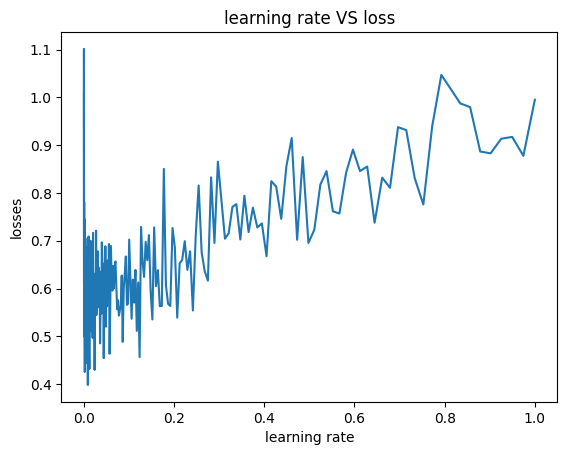

,Layer_type,output shape,#parameters
0,Conv2d 1,"(nan , 32 , 32 , 32 )",2400
1,BatchNorm2d 1,"(nan , 32 , 32 , 32 )",64
2,ReLU 1,"(nan , 32 , 32 , 32 )",0
3,Pooling2d 1,"(nan , 32 , 16 , 16 )",0
4,Conv2d 2,"(nan , 64 , 14 , 14 )",51200
5,BatchNorm2d 2,"(nan , 64 , 14 , 14 )",128
6,ReLU 2,"(nan , 64 , 14 , 14 )",0
7,Pooling2d 2,"(nan , 64 , 7 , 7 )",0
8,Flatten 1,"(nan , 3136 )",0
9,Linear 1,"(nan , 120 )",376440


total number of parameters: 441654


None

In [9]:
# construct the model
g = torch.Generator().manual_seed(2882001)
model = Sequential(
    Conv2d(num_filters = 32, filter_size = (5,5), in_channels=3,padding = 2, bias=False, generator = g),
    BatchNorm2d(32,momentum = 0.999),
    ReLU(),
    Pooling2d(kernel_size = 2 ,pool_type = 'MAX'),
    Conv2d(num_filters = 64, filter_size = (5,5), in_channels=32,padding = 1,bias=False,generator = g), 
    BatchNorm2d(64,momentum = 0.999),ReLU(),
    Pooling2d(kernel_size = 2 ,pool_type = 'MAX'),
    Flatten(),
    Linear(in_dim= 7*7*64, out_dim =120,generator = g),
    BatchNorm(120),ReLU(),
    Linear(in_dim= 120 , out_dim = 84, generator = g), 
    BatchNorm(84),ReLU(),
    Linear(in_dim= 84 , out_dim = 10, generator = g)
)
# construct the optimizer and the lr schedual
parameters = model.parameters()
weight_decay = lambdas[1] * 5
warmup,algo_type = 5, lr_algo[2]
adams = Adams_W(parameters, LR = 0.0018,weight_decay = weight_decay)
lr = LR_schedule(adams, algo_type, epochs, warmup )
CE_loss = cross_entropy_Loss(parameters)
train_engine = Train_engine(model, adams,CE_loss)
lr.set_lr(max_lr_finder(LRs , data_tr_dl , train_engine, lr))

SM = Softmax()
# decrease the weight of the last linear layer so that the weight
# not become biased toweard some specific class
with torch.no_grad():
    model.layers[-1].W *=0.01

#path2 = "/kaggle/working/weights.pt"
#model.load(path2)
eraly_stop = model.EarlyStopping(patience_per=10)

display(model.summary((3 , 32 , 32)))

In [10]:
# claculate the l2 norm of the gradient of the paramters to check if the gradient of the
# earlier layers drop in order of magnitude compared to the final layers gradients or explode in the earlier layers
grad_2norm = [[] for _ in parameters]

# define hooks to gt the percentage of the dead relu
dead_relu_percentage = {}
for module in model.layers:
    if isinstance(module, ReLU):
        name = model.module_names[id(module)]
        module.register_forward_hook(dead_percentage_hook(name, dead_relu_percentage))

In [11]:
# single batch for sanity check 
images, classes = next(iter(data_tr_dl))
image = images[4].unsqueeze(0)
mean = torch.tensor([[[[0.4915]], [[0.4824]], [[0.4469]]]])
std = torch.tensor([[[[0.2469]],[[ 0.2433]],[[0.2615]]]])
image = (image*std )+ mean
class_ = classes[4]


In [12]:
# training loop
losses = []
step = 0
lrs = []
avg_dead_ReLU = []
training_criteria = {'loss':[],'accur': []}
val_criteria = {'loss':[],'accur': []}

for epoch in range(epochs):
    accum_loss = 0
    tr_acc = 0
    dead_ReLU = []
    for images, classes in tqdm(data_tr_dl , desc = 'iterations'):
        lr.step(epoch)
        loss, logits = train_engine.step(images , classes)
        accum_loss += loss
        
        #calculate the l2 norm of the gradients
        # calculate the dea relus 
        dead_ReLU.append(list(dead_relu_percentage.values()))
        for i, p in enumerate(parameters):
            with torch.no_grad():
                grad_2norm[i].append(p.grad.norm(2).item())
        
        # measure the training accuracy
        with torch.no_grad():
            pred = torch.argmax(SM(logits),dim = 1)
            tr_acc += (pred == classes).float().mean()
            
    model.eval()
    avg_dead_ReLU.append(np.mean(dead_ReLU, axis = 0))

    # training Ctriteria
    avg_tr_loss = accum_loss/len(data_tr_dl)
    avg_tr_accuracy = tr_acc/len(data_tr_dl) * 100
    training_criteria['loss'].append(avg_tr_loss)
    training_criteria['accur'].append(avg_tr_accuracy)

    # validation Criteria
    avg_val_loss, avg_val_accuracy = total_loss_accur(model,data_val_dl)
    val_criteria['loss'].append(avg_val_loss)
    val_criteria['accur'].append(avg_val_accuracy)
    
    # training reports
    print(f'epoch: {epoch+1}/{epochs} |'
          f'avg train loss: {avg_tr_loss:.4f} |' 
          f'avg val loss: {avg_val_loss:.4f}'
         )
    print(
          f'avg train accuracy: {avg_tr_accuracy:.4f} % |' 
          f'avg val accuracy: {avg_val_accuracy:.4f} %'
         )

    stop, best_val= eraly_stop(avg_val_loss)
    if stop:
        print(f"break to avoid over fitting with best val loss: {best_val}")
        model.load(model.best_param)
        break

iterations: 100%|██████████| 625/625 [05:29<00:00,  1.90it/s]


epoch: 1/60 |avg train loss: 2.3025 |avg val loss: 2.3016
avg train accuracy: 10.6025 % |avg val accuracy: 11.6000 %


iterations: 100%|██████████| 625/625 [05:18<00:00,  1.96it/s]


epoch: 2/60 |avg train loss: 1.7808 |avg val loss: 1.7725
avg train accuracy: 35.5825 % |avg val accuracy: 38.8200 %


iterations: 100%|██████████| 625/625 [05:20<00:00,  1.95it/s]


epoch: 3/60 |avg train loss: 1.4061 |avg val loss: 1.3730
avg train accuracy: 49.0150 % |avg val accuracy: 52.9100 %


... (110 outputs left out)

iterations: 100%|██████████| 625/625 [05:40<00:00,  1.84it/s]


epoch: 59/60 |avg train loss: 0.4355 |avg val loss: 0.5268
avg train accuracy: 84.5950 % |avg val accuracy: 81.8800 %


iterations: 100%|██████████| 625/625 [05:57<00:00,  1.75it/s]


epoch: 60/60 |avg train loss: 0.4402 |avg val loss: 0.5272
avg train accuracy: 84.6150 % |avg val accuracy: 81.8900 %


In [13]:
# save the weights
model.save("state_dictionary.pt")

# Analysis

## loss and accuracy curves

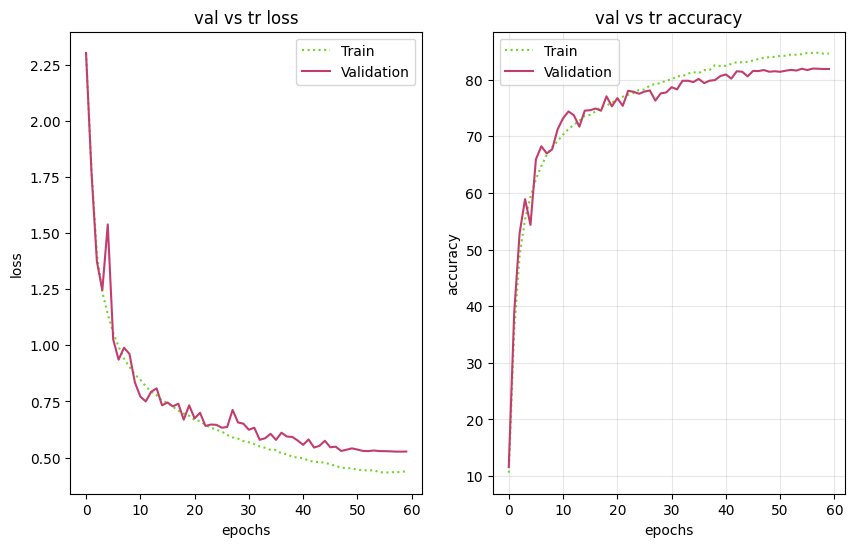

In [14]:

loss_accuracy_visualization(training_criteria,val_criteria)

## sanity check
Before running a full epoch, you must prove the architecture can learn by training the model only on one batch for 50 or 100 itertions.
If your loss doesn't rapidly approach zero and accuracy doesn't hit 100%, you have a fundamental bug. It instantly rules out architectural bottlenecks, silent graph disconnections, or severe optimizer misconfigurations before you waste hours training.

In [15]:
#sanity check
#senity_check({'images':images, 'classes':classes},train_engine)


## Dead/Saturated Activation Tracking
track the percentage of dead neurons during the training process if 40% neurons dead :
* At the beginning: bad initialisation may kill neurons immediately.
* During training: large learning rates or weight updates may gradually kill neurons.
* Near convergence: some neurons may become permanently inactive.

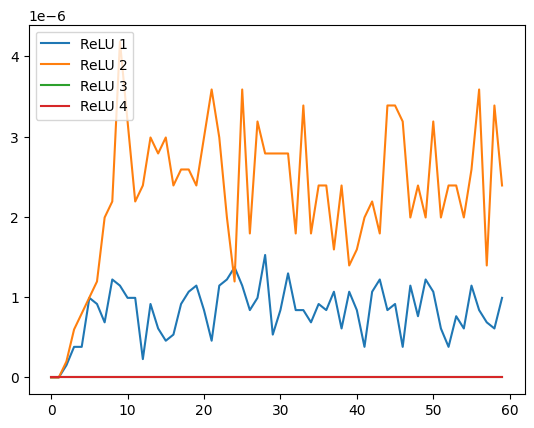

In [16]:
#track the activaion dead neuron percentage
legends =[]
avg_dead = np.array(avg_dead_ReLU)
for i in range(avg_dead.shape[1]):
    plt.plot(avg_dead[:,i])
    legends.append(f'ReLU {i+1}')
plt.legend(legends)
plt.show()

## Gradient Norm Tracking
we monitor the gradient i the backword pass, by computing the L2 norm for each layer gradient to see if the signal survive through the trip and reach the earlier layers.

If the gradient norm in your first convolutional layer drops by orders of magnitude compared to your final fully connected layer, you are experiencing vanishing gradients.

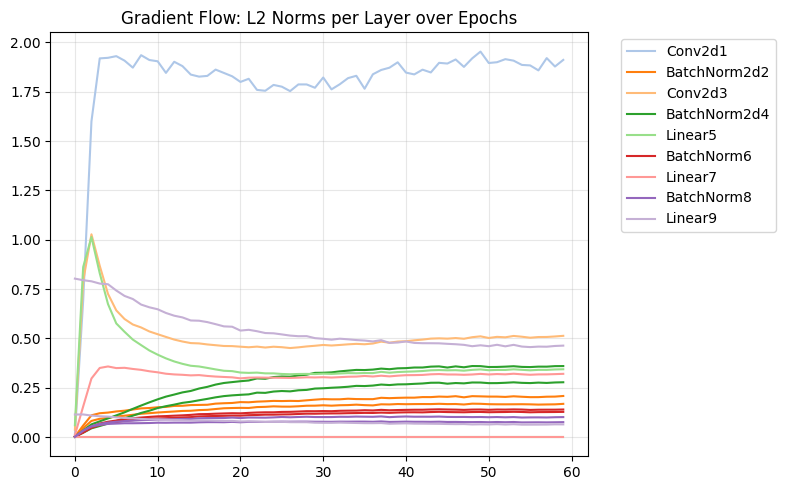

In [17]:
plt.figure(figsize=(8, 5))
title = "Gradient Flow: L2 Norms per Layer over Epochs"
x_label = "Epochs"
y_labe = "Average Gradient L2 Norm"
plot_gradient_flow(model, grad_2norm,iterations, title)
plt.show()

## The Update-to-Weight Ratio
It measures how much the weights are actually changing relative to their current scale.
it's calculated by the ratio between the standard deviation of the weight update step and the standard deviation of the weights themselves.
The ideal ratio is typically around 10^{-3} or -3 in log scale:
* If the ratio is -1 or -2, the step size is too violent, and the network will struggle to settle into a ravine (pathological curvature).
* If the ratio is -5 or -6, the weights are barely moving, and training has effectively stalled. the gradient vanish or the learning rate is too small

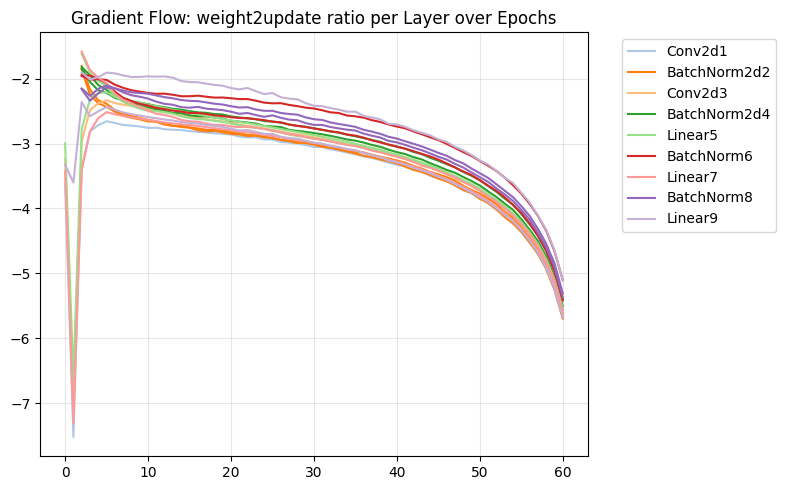

In [18]:
plt.figure(figsize=(8, 5))
title = "Gradient Flow: weight2update ratio per Layer over Epochs"
x_label = "Epochs"
y_labe = "Average weight2update ratio"
plot_gradient_flow(model, adams.Update_to_Weight_Ratio,iterations, title)
plt.show()

# Visualization

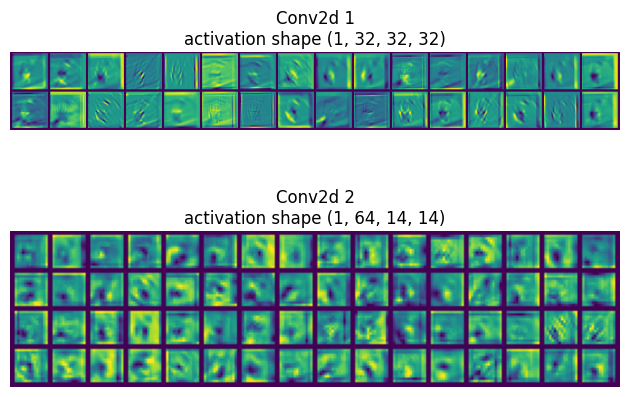

In [19]:
# visualize the layers output
conv_indices = [
    i for i, layer in enumerate(model.layers)
    if isinstance(layer, Conv2d)
]

fig, axes = plt.subplots(len(conv_indices), 1)

if len(conv_indices) == 1:
    axes = [axes]

for ax, i in zip(axes, conv_indices):
    display_layer_out(ax, i, model, image)

plt.tight_layout()
plt.show()

gradient_iterations: 100%|██████████| 150/150 [00:01<00:00, 90.73it/s]


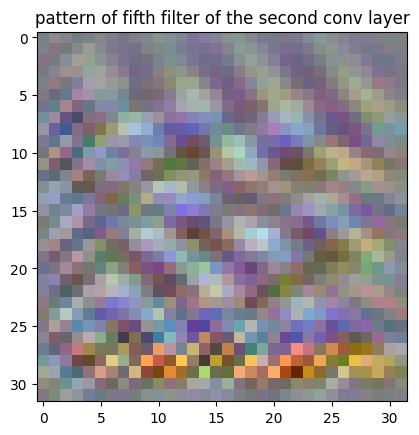

In [20]:
# implement gradient ascent that maximize the output
# the goal is to visualize the filter structure through maximizing the output ofthat filter
# maximizing the output means that the filter found the template it searched for
img = gradient_ascent(model, 4,10,LR = 0.1,steps = 150,tv_weight=0.5, generator = g)
visualize_image(img, 'pattern of fifth filter of the second conv layer')

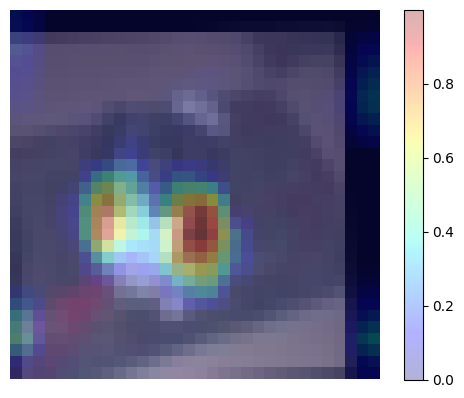

In [21]:
# visualize the feature importance
grad_cam(model, 4, image , class_ )

tensor(5)


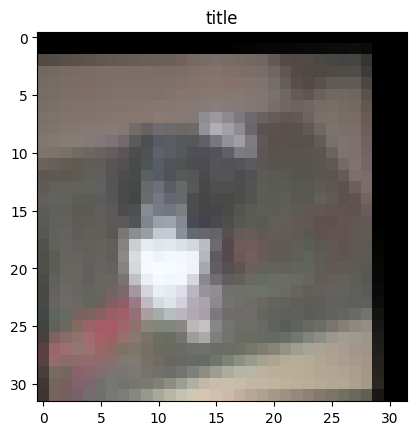

In [22]:
visualize_image(image, 'title')
print(class_)

In [23]:
# legends = []
# for i, layer in enumerate(model.layers):
#     if isinstance(layer,ReLU):
#         print(f'std of ReLU {i}: {layer.out.reshape(-1).std()}')
#         hy,hx = torch.histogram(layer.out,density = True)
#         plt.plot(hx[:-1].detach(),hy.detach())
#         legends.append(f'ReLU {i+1}')
# plt.legend(legends)
# plt.yscale("log")

# LeNet-5
start with LeNet-5(**avg train loss**: 0.0574 |**avg val loss**: 3.3383): **overfitting**
* no regularization technique
* Cosine annealing lr schedual with max lr 0.008
* no batch normalization
* no dropout
* relu activation.
* batch size 64
  
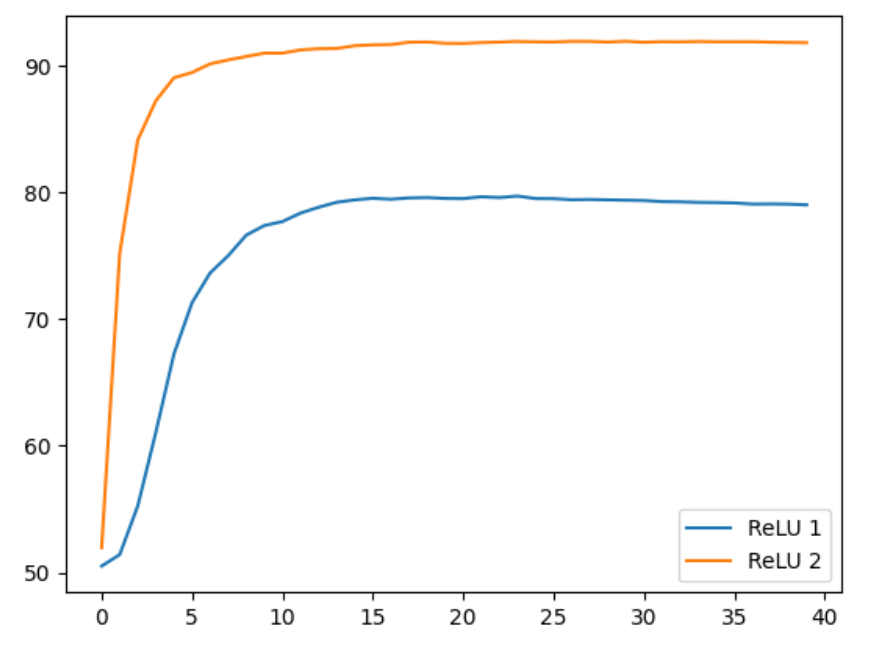

i have found from the graph of dead neurons that more of 80% of the second layer capacity is lost in the warmup phase due to the steep learning rate so i decreaes the max learning rate to the half.

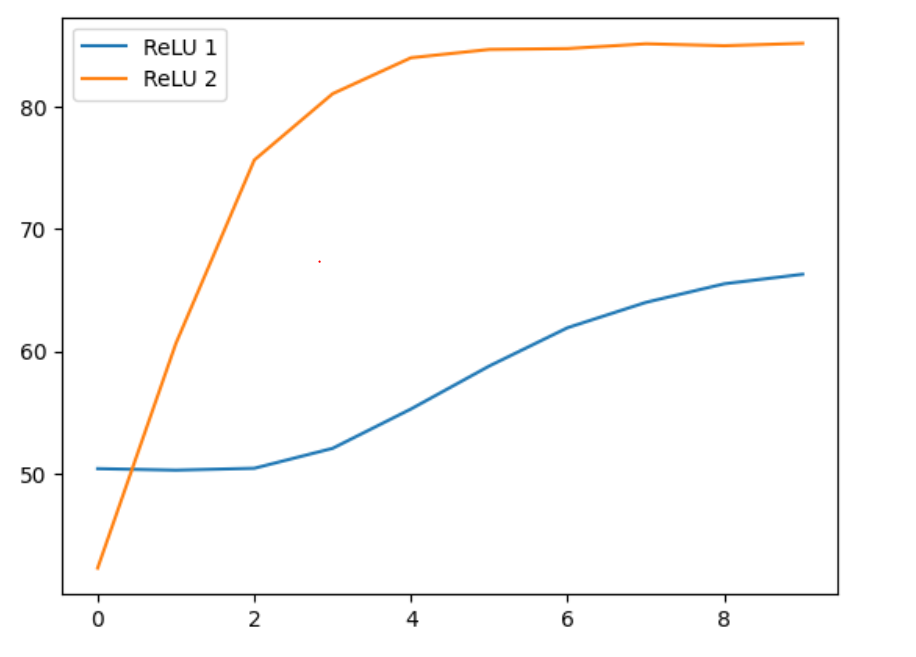
shrinking the learning rate doesn't help so it might be the violent weight update due to gradient so i will use batch normalization layer to  decrease over fitting and metigate the vanishing gradient effect.

the normal behavior is that the curve of the first layer start from 50% becasue kaiming/He inintialization make the input distribution centered around zero, but later the curve must shrink an stepdown as the weight get updated. 

<div style="display:flex; gap:10px;">
    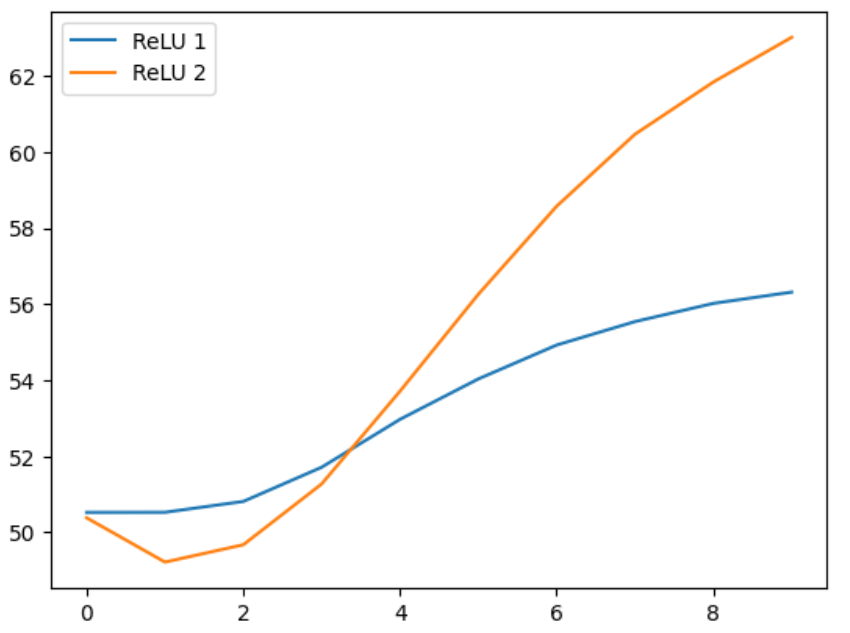
    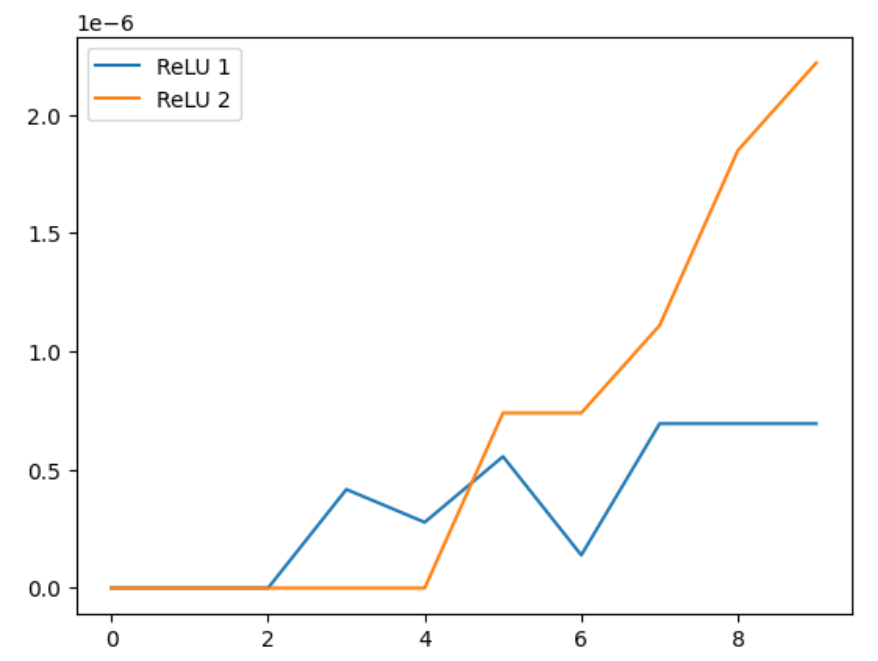
</div>

the waste in resources decrease, we may use leaky relue to give the neuron a chance to relive again.and actually it works

when i look at the gradient norm curve after we use normalization layer i found it reach the healthy state

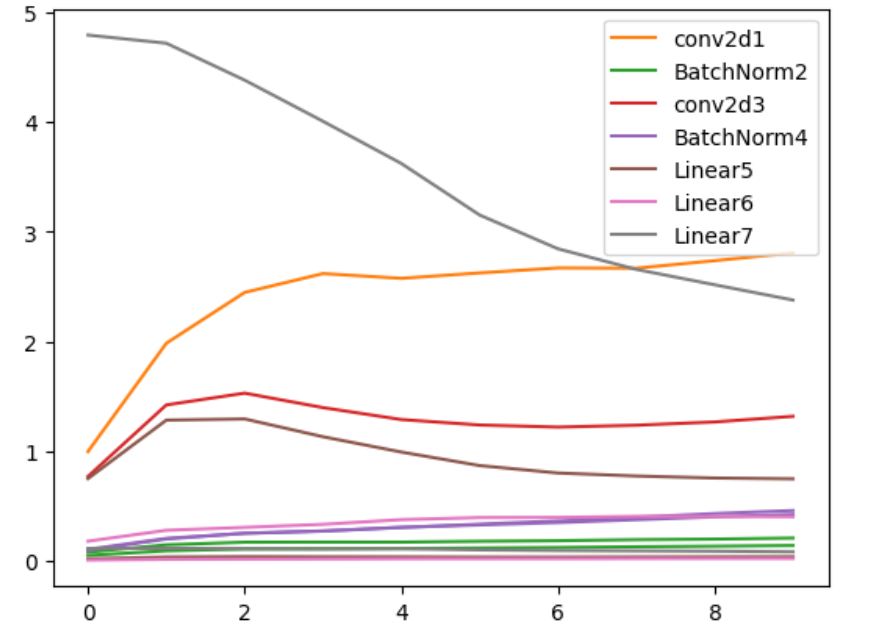

* the final layer start with the highest gradient as the prediction initialy random and the gradient come directly from the loss function. as the training continue the predictions become more confident so the gradient decreas
* the first layer initially receive small gradient as it the upstream gradient has to travel through noisy random routs that will distruct it, but as the network learns, the weights matrices align with the data and the gradient pass become clearer, at the end of convergence the gradient will shrink to 0 and the loss decrease

**use a data_augmenation technique**:
avg train loss: avg train loss: 0.9076 |avg val loss: 0.9270
* without any regularization ( only the batch normalization + pooling regularization effect)
* when i increase the batch size it start overfitting earlier an that comes down that the variation between batchs' statistices decrease and the stochastic noise also decrease which make the model have a bigger chance to fall into local minima.

**the underfitting result from:**
* forgetting to add activations after each MLP linear layer, the data augmentation like color jitter and RandomResizedcrop make the mession difcult for the model with capacity of 20 filter in the firts layer and 40 filter in the second layer.
* i will increase it to 32 and 64, remove randomcrop and add activation layer after each linear one, and i achieved **avg train loss: 0.59 |avg val loss: 0.56**
* use L2 norm with lambda of 1e-6 i achieved **avg train loss: 0.56 |avg val loss: 0.52**
* with padding = 2 in the first conv layer and adams_W that separet the weight decay from the update step i achieved: 

In [24]:
array = torch.tensor([[1,2,3]])
array.repeat_interleave(2, dim = 1)


tensor([[1, 1, 2, 2, 3, 3]])